## CrossVQA Top-Hierarchy Aggregation & Leakage-Free Split Production

This production notebook executes the **Group-First Aggregation and Splitting Pipeline** based on the statistical decisions justified in [`Split_DS_Decision.ipynb`](Split_DS_Decision.ipynb):

1. **Top-Hierarchy Aggregation First:**
   - **DocVQA:** Aggregates all records by parent document (`ucsf_document_id`) $\rightarrow$ `image_count` (distinct pages), `question_count` (queries), `zero_ocr_count`, and `mean_ocr_tokens`.
   - **TextVQA:** Aggregates all records by scene image (`image_id`) $\rightarrow$ `question_count` (queries), `zero_ocr_count`, and `mean_ocr_tokens`.
2. **Group-Level Partitioning (`NEW_train`, `NEW_validation`, `NEW_test`):**
   - Official `validation` groups $\longrightarrow$ **`NEW_test`**.
   - Official `train` groups $\longrightarrow$ **`NEW_train` ($92\%$)** + **`NEW_validation` ($8\%$)** with $|z| > 3.0$ mega-document pinning (`66` DocVQA docs pinned to `NEW_train`, `RANDOM_SEED = 42`).
3. **Artifact Export & GitHub Synchronization:**
   - Exports lightweight parent group tables (`docvqa_document_aggregates`, `textvqa_image_aggregates`) and the compact row-level split manifest (`crossvqa_split_manifest_polars.parquet`) to `DATA_PIPELINE/splits/` and pushes to GitHub.

In [1]:
# ==============================================================================
# 1. ENVIRONMENT SETUP, LOCKED DECISION CONSTANTS & DARK-MODE STYLING
# ==============================================================================
import gc
import json
import math
import os
import sys
import time
import warnings
from pathlib import Path

try:
    import google.colab  # type: ignore
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    print("[Colab VM] Installing / verifying Polars, HF Transfer, and Tabulate...")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-U", "polars", "hf_transfer", "tabulate"],
        check=True,
    )

import numpy as np
import polars as pl
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from huggingface_hub import snapshot_download
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Locked Decision Parameters from Split_DS_Decision.ipynb ---
RECOMMENDED_VAL_SHARE = 0.08   # 8.00% of official train queries -> NEW_validation
Z_THRESHOLD = 3.0              # Pin |z| > 3.0 heavy-tail mega-documents to NEW_train
RANDOM_SEED = 42               # Deterministic cluster sampling seed

# --- Resolve Optional HF_TOKEN ---
HF_TOKEN = os.environ.get("HF_TOKEN") or None
if IN_COLAB and HF_TOKEN is None:
    try:
        from google.colab import userdata  # type: ignore
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

# --- Relative Path Configuration (Strictly Relative to Project Root) ---
if Path.cwd().name == "DATA_PIPELINE":
    os.chdir("..")

REL_ROOT = Path("DATA_PIPELINE")
REL_CACHE_DIR = REL_ROOT / "cache"
REL_FIG_DIR = REL_ROOT / "figures"
REL_SPLIT_DIR = REL_ROOT / "splits"

for _d in (REL_CACHE_DIR, REL_FIG_DIR, REL_SPLIT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# --- Visualization Theme Switch: "dark" (Default for Colab Dark UI) or "light" ---
PLOT_THEME = "dark"

def apply_plot_theme(theme: str = "dark") -> dict:
    if theme == "dark":
        plt.style.use("dark_background")
        palette = {
            "textvqa": "#FB923C",
            "docvqa": "#38BDF8",
            "train": "#60A5FA",
            "val": "#34D399",
            "test": "#F472B6",
            "accent": "#FBBF24",
            "slate": "#52525B",
            "text": "#F4F4F5",
            "bg_fig": "#18181B",
            "bg_ax": "#27272A",
            "grid": "#3F3F46",
        }
        plt.rcParams.update({
            "figure.facecolor": palette["bg_fig"],
            "axes.facecolor": palette["bg_ax"],
            "axes.edgecolor": palette["slate"],
            "axes.labelcolor": palette["text"],
            "xtick.color": palette["text"],
            "ytick.color": palette["text"],
            "text.color": palette["text"],
            "grid.color": palette["grid"],
            "grid.alpha": 0.45,
            "legend.facecolor": palette["bg_ax"],
            "legend.edgecolor": palette["slate"],
            "figure.dpi": 130,
            "savefig.dpi": 150,
            "axes.titleweight": "bold",
            "axes.labelweight": "bold",
            "axes.linewidth": 1.0,
        })
    else:
        sns.set_theme(style="whitegrid", palette="colorblind")
        palette = {
            "textvqa": "#D55E00",
            "docvqa": "#0072B2",
            "train": "#0072B2",
            "val": "#009E73",
            "test": "#CC79A7",
            "accent": "#E69F00",
            "slate": "#222222",
            "text": "#111111",
            "bg_fig": "#FFFFFF",
            "bg_ax": "#FFFFFF",
            "grid": "#E0E0E0",
        }
    return palette

PALETTE = apply_plot_theme(PLOT_THEME)

try:
    from tabulate import tabulate
except ImportError:
    tabulate = None

def display_markdown_table(df: pl.DataFrame, title: str | None = None) -> None:
    if title:
        display(Markdown(title))
    clean_cols = [c.replace("|", r"\|") for c in df.columns]
    df_clean = df.rename(dict(zip(df.columns, clean_cols)))
    if tabulate is not None:
        display(Markdown(tabulate(df_clean.to_dicts(), headers="keys", tablefmt="pipe")))
    else:
        display(Markdown(df_clean.to_pandas().to_markdown(index=False)))

print(f"Environment: {'Google Colab VM' if IN_COLAB else 'Local Runtime'} | Polars {pl.__version__}")
print(f"Locked Protocol -> Val Share: {RECOMMENDED_VAL_SHARE*100:.2f}% | Outlier Pin: |z| > {Z_THRESHOLD} | Seed: {RANDOM_SEED}")

[Colab VM] Installing / verifying Polars, HF Transfer, and Tabulate...
Environment: Google Colab VM | Polars 2.1.0
Locked Protocol -> Val Share: 8.00% | Outlier Pin: |z| > 3.0 | Seed: 42


In [2]:
# ==============================================================================
# 2. ENSURE CANONICAL PARQUET SHARDS ARE PRESENT ON COLAB VM DISK
# ==============================================================================
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"

HF_DATASETS = {
    "textvqa": {
        "repo_id": "gamusa/textvqa-canonical",
        "revision": "d1dcf73eda54e82e84f69d0265f3a9e663420583",
        "label": "TextVQA",
        "domain": "scene_text",
        "local_dir": Path("/content/data/textvqa") if IN_COLAB else REL_ROOT / "data" / "textvqa",
        "cache_file": REL_CACHE_DIR / "textvqa_polars_meta.parquet",
    },
    "docvqa": {
        "repo_id": "gamusa/docvqa-canonical",
        "revision": "86e379d727ab104301e3639b909bfbddb0af6376",
        "label": "DocVQA",
        "domain": "document_text",
        "local_dir": Path("/content/data/docvqa") if IN_COLAB else REL_ROOT / "data" / "docvqa",
        "cache_file": REL_CACHE_DIR / "docvqa_polars_meta.parquet",
    },
}

def ensure_dataset_on_vm(ds_key: str, force_download: bool = False) -> Path:
    cfg = HF_DATASETS[ds_key]
    target_dir = cfg["local_dir"]
    target_dir.mkdir(parents=True, exist_ok=True)

    existing_shards = list(target_dir.glob("**/*.parquet"))
    if existing_shards and not force_download:
        print(f"[{cfg['label']}] Reusing {len(existing_shards)} local Parquet shards in {target_dir.as_posix()}")
        return target_dir

    print(f"[{cfg['label']}] Downloading shards from {cfg['repo_id']}@{cfg['revision'][:10]}...")
    t0 = time.time()
    snapshot_download(
        repo_id=cfg["repo_id"],
        repo_type="dataset",
        revision=cfg["revision"],
        local_dir=str(target_dir),
        allow_patterns=["*.parquet", "**/*.parquet"],
        max_workers=8,
        token=HF_TOKEN,
    )
    shards = list(target_dir.glob("**/*.parquet"))
    print(f"[{cfg['label']}] Downloaded {len(shards)} shards in {time.time() - t0:.1f}s")
    return target_dir

for _k in HF_DATASETS:
    ensure_dataset_on_vm(_k)

[TextVQA] Reusing 16 local Parquet shards in /content/data/textvqa
[DocVQA] Reusing 57 local Parquet shards in /content/data/docvqa


In [3]:
# ==============================================================================
# 3. LIGHTWEIGHT POLARS SCAN & HIERARCHY KEY EXTRACTION
# ==============================================================================
REQUIRED_COLUMNS = [
    "sample_id",
    "domain_type",
    "split",
    "question_id",
    "image_id",
    "ocr_tokens",
    "metadata",
]

def scan_minimal_metadata_polars(ds_key: str, force_refresh: bool = False) -> pl.DataFrame:
    cfg = HF_DATASETS[ds_key]
    cache_path = cfg["cache_file"]

    if cache_path.exists() and not force_refresh:
        df = pl.read_parquet(cache_path)
        print(f"[{cfg['label']}] Loaded cached metadata: {cache_path.as_posix()} ({df.height:,} rows)")
        return df

    data_dir = cfg["local_dir"]
    local_shards = list(data_dir.glob("**/*.parquet"))
    if not local_shards:
        raise FileNotFoundError(f"No Parquet shards found in {data_dir}. Run Cell 2 first!")

    schema = pq.read_schema(local_shards[0])
    avail_cols = [c for c in REQUIRED_COLUMNS if c in schema.names]

    df = (
        pl.scan_parquet(str(data_dir / "**" / "*.parquet"))
        .select(avail_cols)
        .filter(pl.col("split").is_in(["train", "validation"]))
        .collect()
    )

    exprs = [
        pl.col("ocr_tokens").list.len().fill_null(0).cast(pl.UInt16).alias("ocr_token_count"),
    ]
    if ds_key == "docvqa":
        exprs.extend([
            pl.col("metadata")
            .str.json_path_match("$.ucsf_document_id")
            .fill_null(pl.col("image_id").str.extract(r"^([^_]+)", 1))
            .alias("ucsf_document_id"),
            pl.col("metadata")
            .str.json_path_match("$.ucsf_document_page_no")
            .cast(pl.UInt16, strict=False)
            .fill_null(1)
            .alias("ucsf_page_no"),
        ])

    drop_cols = [c for c in ("ocr_tokens", "metadata") if c in df.columns]
    df = df.with_columns(exprs).drop(drop_cols)
    df.write_parquet(cache_path, compression="zstd")
    print(f"[{cfg['label']}] Extracted minimal metadata ({df.height:,} rows) -> {cache_path.as_posix()}")
    return df

df_textvqa = scan_minimal_metadata_polars("textvqa")
df_docvqa = scan_minimal_metadata_polars("docvqa")

[TextVQA] Loaded cached metadata: DATA_PIPELINE/cache/textvqa_polars_meta.parquet (39,602 rows)
[DocVQA] Loaded cached metadata: DATA_PIPELINE/cache/docvqa_polars_meta.parquet (44,812 rows)


### Step 1: Aggregate Data by Top-Hierarchy Group
Before executing the split, we aggregate each dataset by `[split, top_group_key]` so official `validation` (`NEW_test`) and official `train` pools are cleanly separated at the parent entity level:
- **DocVQA Top Group (`ucsf_document_id`):** Computes `image_count` (distinct pages), `question_count` (total queries), `zero_ocr_count`, and `mean_ocr_tokens` per parent document (`5,272` parent documents in official `train`; `938` in official `validation`).
- **TextVQA Top Group (`image_id`):** Computes `question_count` (total queries), `zero_ocr_count`, and `mean_ocr_tokens` per scene image (`21,953` scene images in official `train`; `3,166` in official `validation`).

In [4]:
# ==============================================================================
# 4. AGGREGATE BY TOP-HIERARCHY GROUP (DOCUMENT_ID FOR DOCVQA, IMAGE_ID FOR TEXTVQA)
# ==============================================================================

# 1. DocVQA: Group by [split, ucsf_document_id] to preserve official split boundaries cleanly
docvqa_groups_raw = (
    df_docvqa
    .group_by(["split", "ucsf_document_id"])
    .agg([
        pl.col("image_id").n_unique().cast(pl.UInt16).alias("image_count"),
        pl.len().cast(pl.UInt16).alias("question_count"),
        (pl.col("ocr_token_count") == 0).sum().cast(pl.UInt16).alias("zero_ocr_count"),
        pl.col("ocr_token_count").mean().round(2).alias("mean_ocr_tokens"),
    ])
    .rename({"split": "official_split"})
    .sort(["official_split", "question_count", "image_count"], descending=[False, True, True])
)

# 2. TextVQA: Group by [split, image_id]
textvqa_groups_raw = (
    df_textvqa
    .group_by(["split", "image_id"])
    .agg([
        pl.len().cast(pl.UInt16).alias("question_count"),
        (pl.col("ocr_token_count") == 0).sum().cast(pl.UInt16).alias("zero_ocr_count"),
        pl.col("ocr_token_count").mean().round(2).alias("mean_ocr_tokens"),
    ])
    .rename({"split": "official_split"})
    .sort(["official_split", "question_count", "image_id"], descending=[False, True, False])
)

print(f"DocVQA Top-Hierarchy Groups:  {docvqa_groups_raw.height:,} (Train: {docvqa_groups_raw.filter(pl.col('official_split')=='train').height:,} | Val: {docvqa_groups_raw.filter(pl.col('official_split')=='validation').height:,})")
print(f"TextVQA Top-Hierarchy Groups: {textvqa_groups_raw.height:,} (Train: {textvqa_groups_raw.filter(pl.col('official_split')=='train').height:,} | Val: {textvqa_groups_raw.filter(pl.col('official_split')=='validation').height:,})")

display_markdown_table(
    docvqa_groups_raw.filter(pl.col("official_split") == "train").head(10),
    "#### Preview: Top 10 DocVQA Official `train` Parent Documents (`ucsf_document_id`)"
)
display_markdown_table(
    textvqa_groups_raw.filter(pl.col("official_split") == "train").head(10),
    "#### Preview: Top 10 TextVQA Official `train` Scene Images (`image_id`)"
)

DocVQA Top-Hierarchy Groups:  6,210 (Train: 5,272 | Val: 938)
TextVQA Top-Hierarchy Groups: 25,119 (Train: 21,953 | Val: 3,166)


#### Preview: Top 10 DocVQA Official `train` Parent Documents (`ucsf_document_id`)

| official_split   | ucsf_document_id   |   image_count |   question_count |   zero_ocr_count |   mean_ocr_tokens |
|:-----------------|:-------------------|--------------:|-----------------:|-----------------:|------------------:|
| train            | qjgn0226           |           133 |              716 |                0 |             89.44 |
| train            | xrcy0227           |            79 |              343 |                0 |            145.05 |
| train            | hnnp0227           |            54 |              304 |                0 |            239.44 |
| train            | kzng0227           |            39 |              275 |                0 |            181.74 |
| train            | snyc0227           |            34 |              208 |                0 |            217.5  |
| train            | jybx0223           |            41 |              179 |                0 |            358.46 |
| train            | pnbx0223           |            36 |              167 |                0 |            435.78 |
| train            | jnjm0223           |            28 |              161 |                0 |            199.07 |
| train            | mnbx0223           |            28 |              135 |                0 |            399.99 |
| train            | nnbx0223           |            23 |              133 |                0 |            431.44 |

#### Preview: Top 10 TextVQA Official `train` Scene Images (`image_id`)

| official_split   | image_id         |   question_count |   zero_ocr_count |   mean_ocr_tokens |
|:-----------------|:-----------------|-----------------:|-----------------:|------------------:|
| train            | 0000599864fd15b3 |                2 |                0 |                 8 |
| train            | 00012db06b98f573 |                2 |                0 |                 1 |
| train            | 00016982f6086d39 |                2 |                0 |                29 |
| train            | 000209d575f3aa4f |                2 |                0 |                 8 |
| train            | 000228608388803f |                2 |                0 |                 6 |
| train            | 0002cb8d8ea5eb7e |                2 |                0 |                10 |
| train            | 0002d070329eb0fc |                2 |                0 |                 4 |
| train            | 0002f9c7fac5f093 |                2 |                0 |                 3 |
| train            | 00048f37069b6aa8 |                2 |                0 |                 9 |
| train            | 00066af7b52f505c |                2 |                0 |                 2 |

### Step 2: Execute Leakage-Free Partitioning Based on `Split_DS_Decision.ipynb`
Applies the locked decision protocol (`RECOMMENDED_VAL_SHARE = 0.08`, `Z_THRESHOLD = 3.0`, `RANDOM_SEED = 42`) to partition the top-hierarchy groups into `NEW_train`, `NEW_validation`, and `NEW_test`, then joins `NEW_split` back to both the parent group tables and the row-level sample manifests.

In [5]:
# ==============================================================================
# 5. EXECUTE GROUP-LEVEL SPLITTING & STRICT ZERO-LEAKAGE ASSERTIONS
# ==============================================================================
def execute_group_decision_split(
    df_samples: pl.DataFrame,
    df_groups: pl.DataFrame,
    dataset_name: str,
    group_col: str,
    target_val_share: float = RECOMMENDED_VAL_SHARE,
    z_cutoff: float = Z_THRESHOLD,
    pin_outliers: bool = True,
    seed: int = RANDOM_SEED,
) -> tuple[pl.DataFrame, pl.DataFrame]:
    """
    Uses the aggregated top-hierarchy group table (`df_groups`) to identify heavy-tail
    outliers (|z| > z_cutoff), partitions official `train` groups into `NEW_train` and
    `NEW_validation`, and assigns official `validation` to `NEW_test`.
    Returns (df_samples_split, df_groups_split).
    """
    df_train_samples = df_samples.filter(pl.col("split") == "train")
    df_train_groups = df_groups.filter(pl.col("official_split") == "train")

    n_train_rows = df_train_samples.height
    target_val_rows = int(round(n_train_rows * target_val_share))

    pinned_groups: set[str] = set()
    if pin_outliers and "image_count" in df_train_groups.columns:
        q_cut = float(df_train_groups["question_count"].mean()) + z_cutoff * float(df_train_groups["question_count"].std())
        p_cut = float(df_train_groups["image_count"].mean()) + z_cutoff * float(df_train_groups["image_count"].std())

        mega_df = df_train_groups.filter(
            (pl.col("question_count") > q_cut) | (pl.col("image_count") > p_cut)
        )
        pinned_groups = set(mega_df[group_col].to_list())
        print(
            f"[{dataset_name}] Pinned {len(pinned_groups)} heavy-tail mega-documents "
            f"(abs(z) > {z_cutoff:.1f}, {int(mega_df['question_count'].sum()):,} queries) to NEW_train."
        )

    # Filter to inlier pool for deterministic GroupShuffleSplit
    df_inliers = (
        df_train_samples.filter(~pl.col(group_col).is_in(list(pinned_groups)))
        if pinned_groups else df_train_samples
    )
    adjusted_val_fraction = min(max(target_val_rows / df_inliers.height, 0.01), 0.50)

    gss = GroupShuffleSplit(n_splits=1, test_size=adjusted_val_fraction, random_state=seed)
    groups_array = df_inliers[group_col].to_numpy()
    _, val_idx = next(gss.split(np.zeros(df_inliers.height), groups=groups_array))

    val_groups = set(df_inliers[group_col].gather(val_idx).unique().to_list())

    # 1. Assign NEW_split on the Aggregated Top-Hierarchy Group Table
    df_groups_split = df_groups.with_columns(
        pl.when(pl.col("official_split") == "validation")
        .then(pl.lit("NEW_test"))
        .when(pl.col(group_col).is_in(list(val_groups)))
        .then(pl.lit("NEW_validation"))
        .otherwise(pl.lit("NEW_train"))
        .alias("NEW_split"),
        pl.when(pl.col("official_split") == "train")
        .then(pl.col(group_col).is_in(list(pinned_groups)))
        .otherwise(pl.lit(False))
        .alias("is_pinned_outlier"),
    )

    # 2. Assign NEW_split on the Sample-Level DataFrame
    df_samples_split = df_samples.with_columns(
        pl.when(pl.col("split") == "validation")
        .then(pl.lit("NEW_test"))
        .when(pl.col(group_col).is_in(list(val_groups)))
        .then(pl.lit("NEW_validation"))
        .otherwise(pl.lit("NEW_train"))
        .alias("NEW_split"),
        pl.col(group_col).alias("group_key"),
    )

    # --- Strict Integrity Assertions ---
    tr_part = df_samples_split.filter(pl.col("NEW_split") == "NEW_train")
    va_part = df_samples_split.filter(pl.col("NEW_split") == "NEW_validation")
    te_part = df_samples_split.filter(pl.col("NEW_split") == "NEW_test")

    tr_grps = set(tr_part["group_key"].unique().to_list())
    va_grps = set(va_part["group_key"].unique().to_list())
    tr_imgs = set(tr_part["image_id"].unique().to_list())
    va_imgs = set(va_part["image_id"].unique().to_list())

    assert len(tr_grps & va_grps) == 0, f"FATAL: Group leakage detected in {dataset_name}!"
    assert len(tr_imgs & va_imgs) == 0, f"FATAL: Image leakage detected in {dataset_name}!"
    assert tr_part.height + va_part.height == n_train_rows, "Train row conservation failed!"
    assert df_samples_split.height == df_samples.height, "Total dataset row conservation failed!"

    print(f"[{dataset_name}] Split Verification PASSED:")
    print(f"  • NEW_train:      {tr_part.height:,} queries ({tr_part.height/n_train_rows*100:.2f}% of train) | {len(tr_grps):,} groups")
    print(f"  • NEW_validation: {va_part.height:,} queries ({va_part.height/n_train_rows*100:.2f}% of train) | {len(va_grps):,} groups")
    print(f"  • NEW_test:       {te_part.height:,} queries ({te_part.height/df_samples.height*100:.2f}% of total) | {te_part['group_key'].n_unique():,} groups")
    print(f"  • Leakage Check:  0 shared groups, 0 shared images between NEW_train and NEW_validation\n")

    return df_samples_split, df_groups_split

df_textvqa_split, textvqa_img_agg = execute_group_decision_split(
    df_textvqa, textvqa_groups_raw, dataset_name="TextVQA", group_col="image_id", pin_outliers=False
)
df_docvqa_split, docvqa_doc_agg = execute_group_decision_split(
    df_docvqa, docvqa_groups_raw, dataset_name="DocVQA", group_col="ucsf_document_id", pin_outliers=True
)

[TextVQA] Split Verification PASSED:
  • NEW_train:      31,838 queries (92.01% of train) | 20,196 groups
  • NEW_validation: 2,764 queries (7.99% of train) | 1,757 groups
  • NEW_test:       5,000 queries (12.63% of total) | 3,166 groups
  • Leakage Check:  0 shared groups, 0 shared images between NEW_train and NEW_validation

[DocVQA] Pinned 66 heavy-tail mega-documents (abs(z) > 3.0, 6,288 queries) to NEW_train.
[DocVQA] Split Verification PASSED:
  • NEW_train:      36,443 queries (92.35% of train) | 4,776 groups
  • NEW_validation: 3,020 queries (7.65% of train) | 496 groups
  • NEW_test:       5,349 queries (11.94% of total) | 938 groups
  • Leakage Check:  0 shared groups, 0 shared images between NEW_train and NEW_validation



✓ DocVQA Document Aggregates -> DATA_PIPELINE/splits/docvqa_document_aggregates.parquet (38.7 KB) & CSV (267.2 KB)
✓ TextVQA Image Aggregates   -> DATA_PIPELINE/splits/textvqa_image_aggregates.parquet (264.6 KB) & CSV (1184.3 KB)
✓ Unified Split Manifest     -> DATA_PIPELINE/splits/crossvqa_split_manifest_polars.parquet (1168.7 KB, 84,414 rows)



#### Final CrossVQA Partition Audit Table (`NEW_train`, `NEW_validation`, `NEW_test`)

| Dataset   | Partition      |   Query Count | % of Official Train   | % of Total (Train+Val)   |   Unique Images |   Unique Group Keys | Mean / Max Qs per Group   | 95% MoE   | Zero-OCR Queries   | Leakage vs. Train/Val   |
|:----------|:---------------|--------------:|:----------------------|:-------------------------|----------------:|--------------------:|:--------------------------|:----------|:-------------------|:------------------------|
| TextVQA   | NEW_train      |        31,838 | 92.01%                | 80.39%                   |          20,196 |              20,196 | 1.58 / 2                  | ±0.55%    | 815 (2.56%)        | 0 (Strictly Disjoint)   |
| TextVQA   | NEW_validation |         2,764 | 7.99%                 | 6.98%                    |           1,757 |               1,757 | 1.57 / 2                  | ±1.86%    | 61 (2.21%)         | 0 (Strictly Disjoint)   |
| TextVQA   | NEW_test       |         5,000 | N/A (Held-Out)        | 12.63%                   |           3,166 |               3,166 | 1.58 / 2                  | ±1.39%    | 115 (2.30%)        | 0 (Strictly Disjoint)   |
| DocVQA    | NEW_train      |        36,443 | 92.35%                | 81.32%                   |           9,401 |               4,776 | 7.63 / 716                | ±0.51%    | 4 (0.01%)          | 0 (Strictly Disjoint)   |
| DocVQA    | NEW_validation |         3,020 | 7.65%                 | 6.74%                    |             793 |                 496 | 6.09 / 39                 | ±1.78%    | 0 (0.00%)          | 0 (Strictly Disjoint)   |
| DocVQA    | NEW_test       |         5,349 | N/A (Held-Out)        | 11.94%                   |           1,286 |                 938 | 5.70 / 86                 | ±1.34%    | 0 (0.00%)          | 0 (Strictly Disjoint)   |

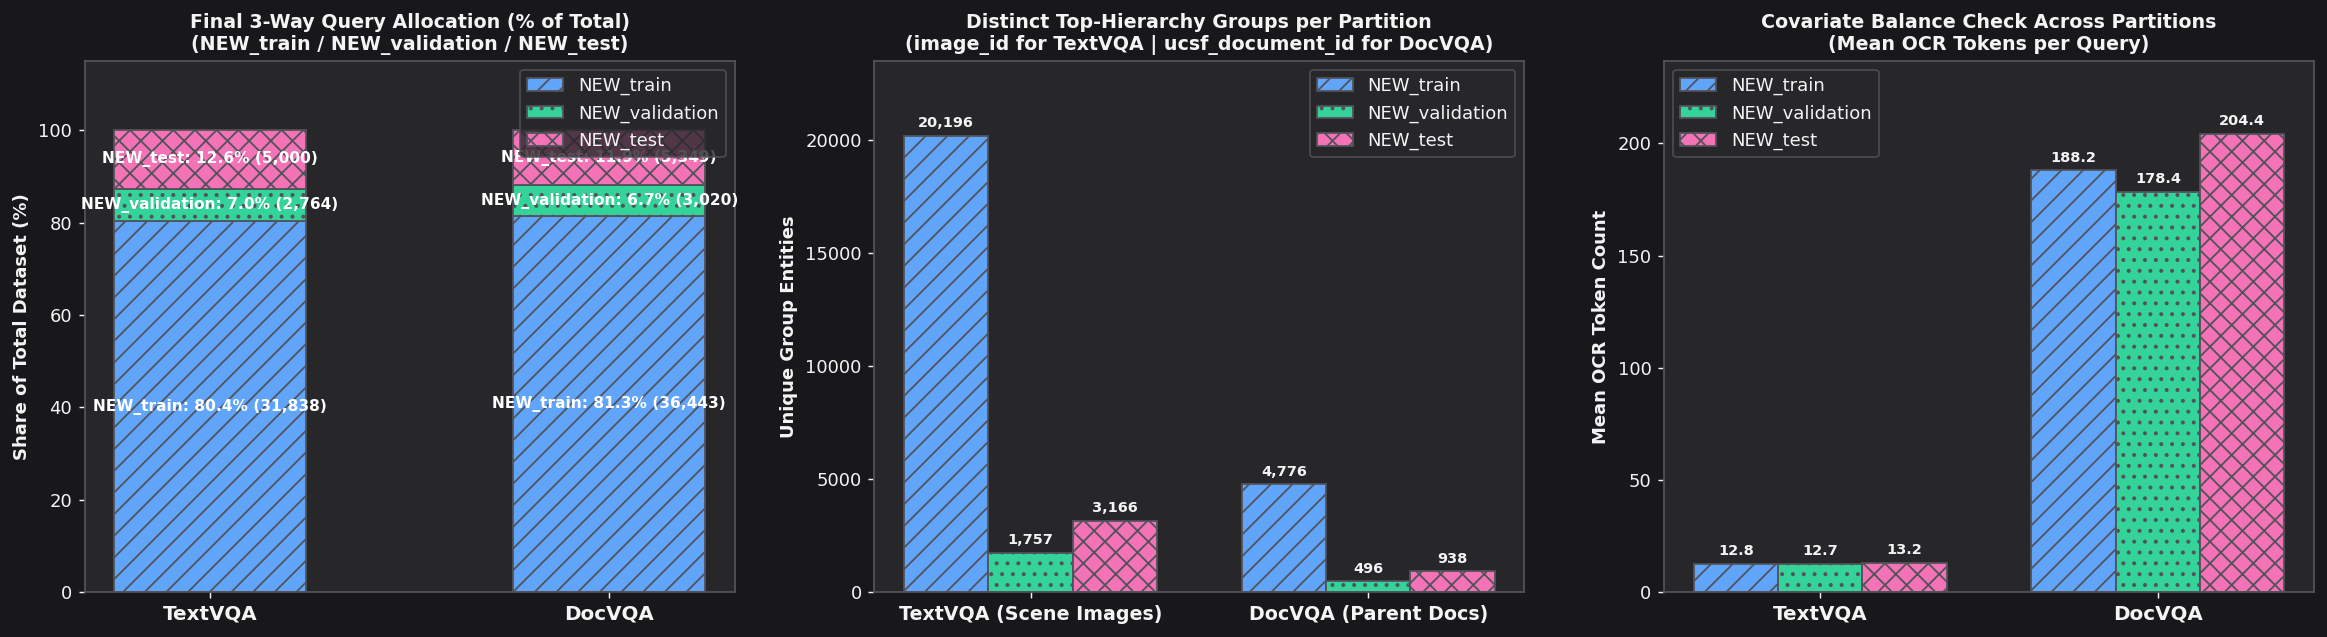

Saved partition summary figure -> DATA_PIPELINE/figures/polars_final_partition_summary.png


In [6]:
# ==============================================================================
# 6. EXPORT GROUP AGGREGATES, SPLIT MANIFEST & RENDER AUDIT SUMMARY
# ==============================================================================

# 1. Export Top-Hierarchy Group Aggregate Tables (Parquet & CSV)
doc_agg_parquet = REL_SPLIT_DIR / "docvqa_document_aggregates.parquet"
doc_agg_csv = REL_SPLIT_DIR / "docvqa_document_aggregates.csv"
txt_agg_parquet = REL_SPLIT_DIR / "textvqa_image_aggregates.parquet"
txt_agg_csv = REL_SPLIT_DIR / "textvqa_image_aggregates.csv"

docvqa_doc_agg.write_parquet(doc_agg_parquet, compression="zstd")
docvqa_doc_agg.write_csv(doc_agg_csv)

textvqa_img_agg.write_parquet(txt_agg_parquet, compression="zstd")
textvqa_img_agg.write_csv(txt_agg_csv)

# 2. Export Compact Unified Row-Level Split Manifest (Parquet)
MANIFEST_COLS = [
    "sample_id",
    "domain_type",
    "split",
    "NEW_split",
    "question_id",
    "image_id",
    "group_key",
    "ocr_token_count",
]

df_unified_manifest = pl.concat(
    [
        df_textvqa_split.select(MANIFEST_COLS).with_columns(pl.lit("textvqa").alias("dataset")),
        df_docvqa_split.select(MANIFEST_COLS).with_columns(pl.lit("docvqa").alias("dataset")),
    ],
    how="vertical",
)

manifest_parquet_path = REL_SPLIT_DIR / "crossvqa_split_manifest_polars.parquet"
df_unified_manifest.write_parquet(manifest_parquet_path, compression="zstd")

print(f"✓ DocVQA Document Aggregates -> {doc_agg_parquet.as_posix()} ({doc_agg_parquet.stat().st_size / 1024:.1f} KB) & CSV ({doc_agg_csv.stat().st_size / 1024:.1f} KB)")
print(f"✓ TextVQA Image Aggregates   -> {txt_agg_parquet.as_posix()} ({txt_agg_parquet.stat().st_size / 1024:.1f} KB) & CSV ({txt_agg_csv.stat().st_size / 1024:.1f} KB)")
print(f"✓ Unified Split Manifest     -> {manifest_parquet_path.as_posix()} ({manifest_parquet_path.stat().st_size / 1024:.1f} KB, {df_unified_manifest.height:,} rows)\n")

# 3. Tabulate Final 6-Partition Audit Summary
final_audit_rows = []
for ds_label, df_s in [("TextVQA", df_textvqa_split), ("DocVQA", df_docvqa_split)]:
    tot_q = df_s.height
    tr_q = df_s.filter(pl.col("split") == "train").height

    for part_name in ["NEW_train", "NEW_validation", "NEW_test"]:
        sub = df_s.filter(pl.col("NEW_split") == part_name)
        n_q = sub.height
        grp_counts = sub.group_by("group_key").agg(pl.len().alias("q_cnt"))["q_cnt"]
        moe_95 = 1.96 * math.sqrt(0.25 / n_q) * 100.0
        zero_ocr = int((sub["ocr_token_count"] == 0).sum())

        final_audit_rows.append({
            "Dataset": ds_label,
            "Partition": part_name,
            "Query Count": f"{n_q:,}",
            "% of Official Train": f"{n_q / tr_q * 100:.2f}%" if part_name != "NEW_test" else "N/A (Held-Out)",
            "% of Total (Train+Val)": f"{n_q / tot_q * 100:.2f}%",
            "Unique Images": f"{sub['image_id'].n_unique():,}",
            "Unique Group Keys": f"{sub['group_key'].n_unique():,}",
            "Mean / Max Qs per Group": f"{float(grp_counts.mean()):.2f} / {int(grp_counts.max())}",
            "95% MoE": f"±{moe_95:.2f}%",
            "Zero-OCR Queries": f"{zero_ocr:,} ({zero_ocr / n_q * 100:.2f}%)",
            "Leakage vs. Train/Val": "0 (Strictly Disjoint)",
        })

df_final_audit_pl = pl.DataFrame(final_audit_rows)
display_markdown_table(
    df_final_audit_pl,
    "#### Final CrossVQA Partition Audit Table (`NEW_train`, `NEW_validation`, `NEW_test`)"
)

# 4. Render 3-Panel Partition Proportions & Covariate Balance Figure
fig, axes = plt.subplots(1, 3, figsize=(18.0, 5.0))
partitions = ["NEW_train", "NEW_validation", "NEW_test"]
part_colors = [PALETTE["train"], PALETTE["val"], PALETTE["test"]]
part_hatches = ["//", "..", "xx"]

x_ds = np.arange(2)
bottoms = np.zeros(2)

for sp_name, col, ht in zip(partitions, part_colors, part_hatches):
    cnts = [
        df_textvqa_split.filter(pl.col("NEW_split") == sp_name).height,
        df_docvqa_split.filter(pl.col("NEW_split") == sp_name).height,
    ]
    tots = [df_textvqa_split.height, df_docvqa_split.height]
    pcts = np.array([c / t * 100 for c, t in zip(cnts, tots)])
    bars = axes[0].bar(x_ds, pcts, width=0.48, bottom=bottoms, color=col, edgecolor=PALETTE["slate"], hatch=ht, label=sp_name)
    for b, pct, cnt, bot in zip(bars, pcts, cnts, bottoms):
        axes[0].annotate(
            f"{sp_name}: {pct:.1f}% ({cnt:,})",
            xy=(b.get_x() + b.get_width()/2, bot + pct/2),
            ha="center", va="center", color="white", fontweight="bold", fontsize=8.5
        )
    bottoms += pcts

axes[0].set_title("Final 3-Way Query Allocation (% of Total)\n(NEW_train / NEW_validation / NEW_test)", fontsize=10.5)
axes[0].set_xticks(x_ds)
axes[0].set_xticklabels(["TextVQA", "DocVQA"], fontweight="bold", fontsize=11)
axes[0].set_ylabel("Share of Total Dataset (%)")
axes[0].set_ylim(0, 115)
axes[0].legend(loc="upper right")

w = 0.25
for idx_p, (sp_name, col, ht) in enumerate(zip(partitions, part_colors, part_hatches)):
    grp_cnts = [
        df_textvqa_split.filter(pl.col("NEW_split") == sp_name)["group_key"].n_unique(),
        df_docvqa_split.filter(pl.col("NEW_split") == sp_name)["group_key"].n_unique(),
    ]
    bars = axes[1].bar(x_ds + (idx_p - 1) * w, grp_cnts, width=w, color=col, edgecolor=PALETTE["slate"], hatch=ht, label=sp_name)
    for b in bars:
        h = int(b.get_height())
        axes[1].annotate(f"{h:,}", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 3),
                         textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")

axes[1].set_title("Distinct Top-Hierarchy Groups per Partition\n(image_id for TextVQA | ucsf_document_id for DocVQA)", fontsize=10.5)
axes[1].set_xticks(x_ds)
axes[1].set_xticklabels(["TextVQA (Scene Images)", "DocVQA (Parent Docs)"], fontweight="bold", fontsize=10.5)
axes[1].set_ylabel("Unique Group Entities")
axes[1].set_ylim(0, 23500)
axes[1].legend(loc="upper right")

for idx_p, (sp_name, col, ht) in enumerate(zip(partitions, part_colors, part_hatches)):
    mean_ocr = [
        float(df_textvqa_split.filter(pl.col("NEW_split") == sp_name)["ocr_token_count"].mean()),
        float(df_docvqa_split.filter(pl.col("NEW_split") == sp_name)["ocr_token_count"].mean()),
    ]
    bars = axes[2].bar(x_ds + (idx_p - 1) * w, mean_ocr, width=w, color=col, edgecolor=PALETTE["slate"], hatch=ht, label=sp_name)
    for b in bars:
        val = b.get_height()
        axes[2].annotate(f"{val:.1f}", xy=(b.get_x() + b.get_width()/2, val), xytext=(0, 3),
                         textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")

axes[2].set_title("Covariate Balance Check Across Partitions\n(Mean OCR Tokens per Query)", fontsize=10.5)
axes[2].set_xticks(x_ds)
axes[2].set_xticklabels(["TextVQA", "DocVQA"], fontweight="bold", fontsize=11)
axes[2].set_ylabel("Mean OCR Token Count")
axes[2].set_ylim(0, max(float(df_docvqa_split["ocr_token_count"].mean()) * 1.25, 200))
axes[2].legend(loc="upper left")

plt.tight_layout()
final_fig_path = REL_FIG_DIR / "polars_final_partition_summary.png"
plt.savefig(final_fig_path, bbox_inches="tight")
plt.show()
print(f"Saved partition summary figure -> {final_fig_path.as_posix()}")

In [10]:
# ==============================================================================
# 7. COMMIT & PUSH GENERATED SPLIT ARTIFACTS TO GITHUB (COLAB VM & LOCAL)
# ==============================================================================
import getpass
import shutil
import subprocess

def sync_splits_to_github(
    repo_slug: str = "NhanChanDeo/VQA_Final_Thesis.git",
    commit_msg: str = "feat(pipeline): add top-hierarchy group aggregates and leakage-free split manifests",
) -> None:
    token = os.environ.get("GITHUB_TOKEN")
    if IN_COLAB and not token:
        try:
            from google.colab import userdata  # type: ignore
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        token = getpass.getpass("Enter GitHub Personal Access Token (or press Enter to skip push): ").strip()
    if not token:
        print("ℹ️ Skipping GitHub push (no token provided). Files are saved in DATA_PIPELINE/splits/.")
        return

    repo_url = f"https://{token}@github.com/{repo_slug}"
    clone_dir = Path("/content/VQA_Final_Thesis_repo") if IN_COLAB else Path("../VQA_Final_Thesis_sync_tmp")

    if clone_dir.exists():
        shutil.rmtree(clone_dir)

    print(f"Cloning {repo_slug} into temporary worktree...")
    subprocess.run(["git", "clone", repo_url, str(clone_dir)], check=True)

    target_split_dir = clone_dir / "DATA_PIPELINE" / "splits"
    target_split_dir.mkdir(parents=True, exist_ok=True)

    for item in REL_SPLIT_DIR.glob("*"):
        if item.is_file() and item.name != "crossvqa_split_manifest_polars.csv":
            shutil.copy2(item, target_split_dir / item.name)
            print(f"  ✓ Copied: {item.name}")

    subprocess.run(["git", "config", "user.name", "NhanChanDeo"], cwd=clone_dir, check=True)
    subprocess.run(["git", "config", "user.email", "pipeline@vqa-thesis.local"], cwd=clone_dir, check=True)
    subprocess.run(["git", "add", "DATA_PIPELINE/splits/"], cwd=clone_dir, check=True)

    status = subprocess.run(["git", "status", "--porcelain"], cwd=clone_dir, capture_output=True, text=True).stdout.strip()
    if not status:
        print("ℹ️ All split artifacts in origin/main are already identical and up-to-date.")
        return

    subprocess.run(["git", "commit", "-m", commit_msg], cwd=clone_dir, check=True)
    subprocess.run(["git", "push", "origin", "HEAD:main"], cwd=clone_dir, check=True)
    print("\n🎉 Successfully committed and pushed split artifacts to GitHub (origin/main)!")

#Uncomment to execute push on Colab VM:
sync_splits_to_github()

Cloning NhanChanDeo/VQA_Final_Thesis.git into temporary worktree...
  ✓ Copied: crossvqa_split_manifest_polars.parquet
  ✓ Copied: textvqa_image_aggregates.parquet
  ✓ Copied: docvqa_document_aggregates.csv
  ✓ Copied: textvqa_image_aggregates.csv
  ✓ Copied: docvqa_document_aggregates.parquet

🎉 Successfully committed and pushed split artifacts to GitHub (origin/main)!
